# Regresión: Random Forest

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "random_forest"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Random Forest
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

Se comparan cuatro variantes del target: nativo, sqrt y log1p (estas dos con corrección de smearing) y pérdida Poisson (`criterion="poisson"`). Su justificación y el sesgo de retransformación se explican en [Variantes del target](#mod-variantes) y [Sesgo de retransformación](#mod-smearing).

### Espacio de Búsqueda

Mismos rangos que en la clasificación (versión `Regressor`). Se exploraron 25 combinaciones por variante: número de árboles (200 a 800), profundidad máxima (3, 5, 8, 12 o sin límite), tamaño mínimo de las hojas (5 a 50) y fracción de predictores por división (`sqrt`, 0.5 o todos).

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
n_estimators,entero entre 200 y 800
max_depth,"3, 5, 8, 12, None"
min_samples_leaf,"5, 10, 20, 50"
max_features,"sqrt, 0.5, 1.0"


### Validación Cruzada por Variante

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.8943 ± 0.4978  R² = 0.2026  (24 s)
✓ sqrt + smearing    RMSE = 6.8948 ± 0.5093  R² = 0.2026  (23 s)
✓ log1p + smearing   RMSE = 6.8932 ± 0.4905  R² = 0.2025  (21 s)
✓ Pérdida Poisson    RMSE = 6.8920 ± 0.4978  R² = 0.2031  (22 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.894 ± 0.498,4.914 ± 0.189,0.203 ± 0.014,24.0
sqrt + smearing,6.895 ± 0.509,4.880 ± 0.187,0.203 ± 0.018,23.0
log1p + smearing,6.893 ± 0.490,4.869 ± 0.182,0.203 ± 0.021,21.0
Pérdida Poisson,6.892 ± 0.498,4.914 ± 0.185,0.203 ± 0.016,22.0


Las cuatro variantes son prácticamente idénticas en RMSE (de 6.892 a 6.895) y en R² (0.203). Las diferencias aparecen solo en el MAE: log1p (4.869) y sqrt (4.880) lo reducen frente al nativo y a la pérdida Poisson (4.914). El Random Forest mejora ligeramente a la regresión lineal (6.900).

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,max_depth,max_features,min_samples_leaf,n_estimators
Variante,,,,
Nativo,NaN,0.5,50,291
sqrt + smearing,5.0,0.5,10,585
log1p + smearing,5.0,0.5,10,469
Pérdida Poisson,5.0,0.5,10,585


Las variantes sqrt, log1p y Poisson eligen árboles poco profundos (`max_depth=5`, con al menos 10 observaciones por hoja). El nativo prefiere árboles sin límite de profundidad pero con hojas grandes (50 observaciones), que es otra forma de regularizar. Todas usan la mitad de los predictores en cada división (`max_features=0.5`), y sqrt y Poisson eligieron exactamente la misma configuración.

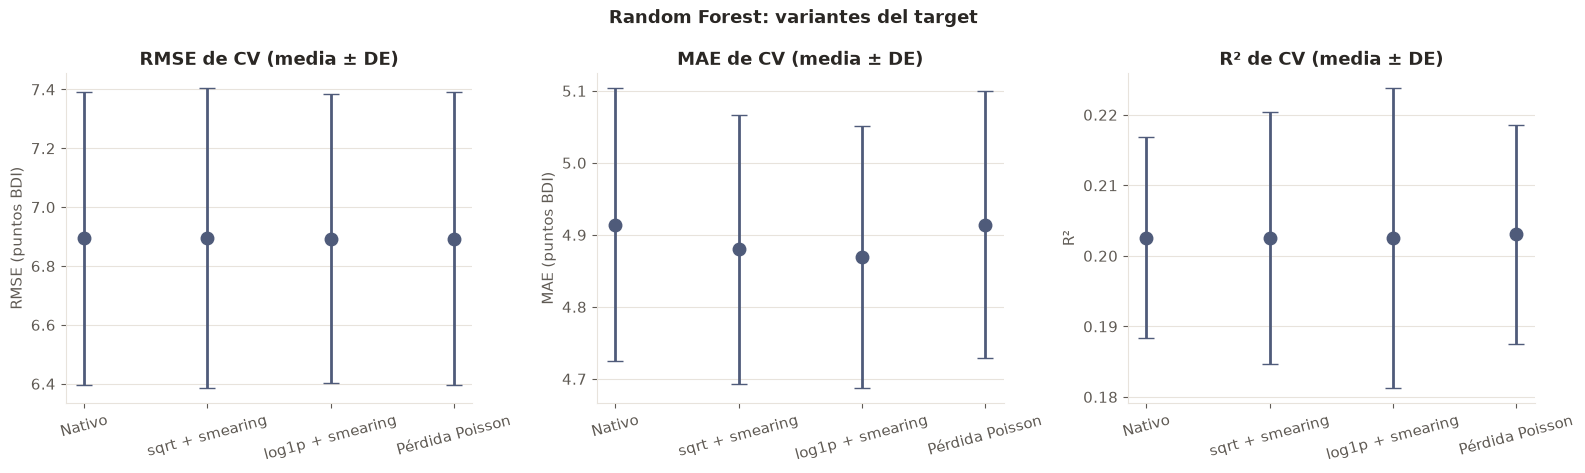

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica confirma que las cuatro variantes son equivalentes: los puntos de RMSE y R² están a la misma altura y las barras de desviación se solapan por completo. Las hojas de los árboles ya promedian a adolescentes parecidos, así que transformar el target o cambiar la pérdida apenas cambia las predicciones.

### Sesgo de Retransformación: Efecto del Smearing

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (log1p + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.078,-2.224,7.292,4.652,0.114
Con smearing,7.183,-0.118,6.911,4.869,0.204


log1p es la mejor variante transformada. Sin smearing, su media predicha es 5.08, 2.22 puntos por debajo de la real, y el R² cae a 0.114. Con la corrección, la media sube a 7.18 y el R² a 0.204. Queda un sesgo de −0.12 puntos porque en un bosque la corrección es parcial.

### Selección del Mejor Modelo Random Forest

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Random Forest
Variante ganadora,Nativo
RMSE de CV,6.8943 ± 0.4978
MAE de CV,4.9143 ± 0.1895
R² de CV,0.2026 ± 0.0142
Hiperparámetros,"max_depth=None, max_features=0.5, min_samples_leaf=50, n_estimators=291"
Criterio,"El menor RMSE medio de CV es el de 'Pérdida Poisson' (6.8920 ± 0.4978), pero 'Nativo' es más simple y su RMSE (6.8943) está a solo 0.0023 puntos, menos que la desviación estándar de CV de la ganadora (0.4978). Por la regla de empate se elige 'Nativo'."


La pérdida Poisson tiene el menor RMSE medio (6.8920), pero su ventaja sobre el nativo es de solo 0.002 puntos, frente a una desviación entre folds de 0.498. Por la regla de empate se elige el nativo.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/random_forest: resultados_cv.csv, ganador.json y random_forest_nativo.joblib
